In [1]:
import sys

# this kernel's numpy (2.1.2) + uproot (5.1.2) combo raises OverflowError reading JetClass
# .root files - prepend the deps folder with compatible versions before anything imports numpy
deps_path = "/home/users/w/wozniak/.local/ntp4jets-deps"
if deps_path not in sys.path:
    sys.path.insert(0, deps_path)

import pyrootutils

pyrootutils.setup_root(__file__ if "__file__" in dir() else ".", indicator=".project-root", pythonpath=True)

import hydra
import numpy as np
import torch
import matplotlib.pyplot as plt
from omegaconf import OmegaConf

from gabbro.models.backbone_multihead import BackboneMultiHeadLightning

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device


device(type='cuda')

## instantiate dataloader and load data: jetclass

In [2]:
from hydra import compose, initialize_config_dir
from hydra.core.global_hydra import GlobalHydra

# `example_experiment_backbone_and_head_allfeat_mpm.yaml`'s `defaults:` list overrides
# `/feature_dict` (-> feature_dict_all_without_cuts.yaml) and `/data` (-> iter_dataset_jetclass_all_types)
# - OmegaConf.load can't apply those group overrides or resolve `${feature_dict}` interpolations,
# only Hydra's compose can. Build the config the same way `train.py`'s `@hydra.main` does.
# This experiment also sets `dataset_kwargs_common.token_id_cfg`, so the dataloader reads
# pre-tokenized *.parquet files (not raw .root) - point data_dir at the tokenized dataset dir
# that's actually accessible here (same one used for training this checkpoint).
GlobalHydra.instance().clear()
with initialize_config_dir(
    config_dir="/home/users/w/wozniak/dev/enhancing-ntp4jets/configs", version_base=None
):
    cfg = compose(
        config_name="train",
        overrides=[
            "experiment=example_experiment_backbone_and_head_allfeat_mpm",
            "data.data_dir=/srv/beegfs/scratch/groups/rodem/lumea/datasets/JetClass/Pythia/"
            "cont_alfa_tokenized_allfeat/2026-08-04_14-03-40_gpu024_EquestrianSymbol",
        ],
    )

print(OmegaConf.to_yaml(cfg.data.dataset_kwargs_common.feature_dict, resolve=True))


part_pt:
  multiply_by: 1
  subtract_by: 1.8
  func: signed_log
  inv_func: signed_exp
part_etarel:
  multiply_by: 3
part_phirel:
  multiply_by: 3
part_mass:
  clip_min_input_space: 0
part_charge: null
part_isChargedHadron: null
part_isNeutralHadron: null
part_isPhoton: null
part_isElectron: null
part_isMuon: null
part_d0val:
  func: signed_log
  inv_func: signed_exp
part_dzval:
  func: signed_log
  inv_func: signed_exp
part_d0err: null
part_dzerr: null



In [3]:
N_JETS = 100_000

# restrict the test split to QCD only, single file (ZJetsToNuNu_* files have 100K jets each,
# so one file already gives us ~100K jets) - everything else (feature_dict, cuts, padding,
# labels_to_load) stays exactly as used for training
cfg.data.dataset_kwargs_test.files_dict = {
    "QCD": cfg.data.dataset_kwargs_test.files_dict.QCD
}
cfg.data.dataset_kwargs_test.max_n_files_per_type = 1
cfg.data.dataset_kwargs_common.labels_to_load = ["label_QCD"]

datamodule = hydra.utils.instantiate(cfg.data)
datamodule.setup(stage="test")

test_dataloader_jetclass = datamodule.test_dataloader()


Parameter seed is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_train(value=42). Using the value from dataset_kwargs_train.
Parameter seed is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_val(value=1). Using the value from dataset_kwargs_val.
Parameter seed_shuffle_data is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_val(value=1). Using the value from dataset_kwargs_val.
Parameter seed_shuffle_data is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_test(value=42). Using the value from dataset_kwargs_test.
Parameter random_seed_for_per_file_shuffling is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_val(value=None). Using the value from dataset_kwargs_val.
random_seed_for_per_file_shuffling is only used if load_only_once is True.
shuffle_files is False. This means that the files list will not be shuffled.
shuffle_files is False. Will not shuffle files and continue w

In [4]:
part_features_list = []
part_mask_list = []
jet_features_list = []

n_collected = 0
for batch in test_dataloader_jetclass:
    part_features_list.append(batch["part_features"])
    part_mask_list.append(batch["part_mask"])
    jet_features_list.append(batch["jet_features"])
    n_collected += batch["part_features"].shape[0]
    if n_collected >= N_JETS:
        break

jetclass_part_features = torch.cat(part_features_list)[:N_JETS].numpy()
jetclass_part_mask = torch.cat(part_mask_list)[:N_JETS].numpy()
jetclass_jet_features = torch.cat(jet_features_list)[:N_JETS].numpy()

print(f"Collected {jetclass_part_features.shape[0]} QCD jets.")
print(f"part_features shape: {tuple(jetclass_part_features.shape)}")
print(f"part_mask shape:     {tuple(jetclass_part_mask.shape)}")
print(f"jet_features shape:  {tuple(jetclass_jet_features.shape)}")


You are clipping the values of the feature 'part_mass' in input space with clip_min_input_space = 0 and clip_max_input_space = None. Make sure this is intended. THIS IS NOT INVERTIBLE.
shuffle_files is False. Will not shuffle files and continue with the previous order.


Collected 100000 QCD jets.
part_features shape: (100000, 100, 14)
part_mask shape:     (100000, 100)
jet_features shape:  (100000, 1)


## Load ~100K jets from the Aspen Open Jets (AOJ) dataset using `dataset_type="aoj"`

Reuses the same config machinery as above, but switches the dataloader to the
`read_cms_open_data_file` codepath (single AOJ h5 file). Note: that reader only
exposes `part_pt`/`part_eta`/`part_phi`/`part_etarel`/`part_phirel` at the particle
level (no charge, PID flags, mass, or impact-parameter fields like the JetClass
reader has), and it doesn't load jet-level features at all - so the feature_dict
is restricted to `feature_dict_kin_massless_without_cuts.yaml` accordingly.

In [5]:
GlobalHydra.instance().clear()
with initialize_config_dir(
    config_dir="/home/users/w/wozniak/dev/enhancing-ntp4jets/configs", version_base=None
):
    cfg_aoj = compose(
        config_name="train",
        overrides=[
            "experiment=example_experiment_backbone_and_head_allfeat_mpm",
            "feature_dict=feature_dict_all_without_cuts",
        ],
    )

AOJ_FILE = "/srv/beegfs/scratch/groups/rodem/lumea/datasets/aspenJets/RunG_batch0.h5"

# switch off the tokenized-parquet codepath and jetclass-only extras, point at the AOJ file
cfg_aoj.data.dataset_kwargs_common.dataset_type = "aoj"
cfg_aoj.data.dataset_kwargs_common.token_id_cfg = None
cfg_aoj.data.dataset_kwargs_common.feature_dict_labels_particles = None
cfg_aoj.data.dataset_kwargs_common.feature_dict_jet = None
cfg_aoj.data.dataset_kwargs_common.labels_to_load = ["label_QCD"]

cfg_aoj.data.data_dir = "/srv/beegfs/scratch/groups/rodem/lumea/datasets/aspenJets"
# `setup(stage="fit")` also builds the val dataset, so point that at the same single file too
cfg_aoj.data.dataset_kwargs_train.files_dict = {"QCD": [AOJ_FILE]}
cfg_aoj.data.dataset_kwargs_train.max_n_files_per_type = 1
cfg_aoj.data.dataset_kwargs_val.files_dict = {"QCD": [AOJ_FILE]}
cfg_aoj.data.dataset_kwargs_val.max_n_files_per_type = 1

print(OmegaConf.to_yaml(cfg_aoj.data.dataset_kwargs_common.feature_dict, resolve=True))

part_pt:
  multiply_by: 1
  subtract_by: 1.8
  func: signed_log
  inv_func: signed_exp
part_etarel:
  multiply_by: 3
part_phirel:
  multiply_by: 3
part_mass:
  clip_min_input_space: 0
part_charge: null
part_isChargedHadron: null
part_isNeutralHadron: null
part_isPhoton: null
part_isElectron: null
part_isMuon: null
part_d0val:
  func: signed_log
  inv_func: signed_exp
part_dzval:
  func: signed_log
  inv_func: signed_exp
part_d0err: null
part_dzerr: null



In [6]:
datamodule_aoj = hydra.utils.instantiate(cfg_aoj.data)
# AOJ has no separate train/val/test split - just read the file(s) directly
datamodule_aoj.setup(stage="fit")

train_dataloader_aoj = datamodule_aoj.train_dataloader()

Parameter seed is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_train(value=42). Using the value from dataset_kwargs_train.
Parameter seed is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_val(value=1). Using the value from dataset_kwargs_val.
Parameter seed_shuffle_data is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_val(value=1). Using the value from dataset_kwargs_val.
Parameter seed_shuffle_data is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_test(value=42). Using the value from dataset_kwargs_test.
Parameter random_seed_for_per_file_shuffling is present in both dataset_kwargs_common (value=12345) and dataset_kwargs_val(value=None). Using the value from dataset_kwargs_val.
random_seed_for_per_file_shuffling is only used if load_only_once is True.
n_files_at_once=10 is larger than the number of files in the dataset (1).
Setting n_files_at_once to 1.
shuffle_files is False. This means

In [7]:
N_JETS_AOJ = 100_000

aoj_part_features_list = []
aoj_part_mask_list = []

n_collected = 0
for batch in train_dataloader_aoj:
    aoj_part_features_list.append(batch["part_features"])
    aoj_part_mask_list.append(batch["part_mask"])
    n_collected += batch["part_features"].shape[0]
    if n_collected >= N_JETS_AOJ:
        break

aoj_part_features = torch.cat(aoj_part_features_list)[:N_JETS_AOJ].numpy()
aoj_part_mask = torch.cat(aoj_part_mask_list)[:N_JETS_AOJ].numpy()

print(f"Collected {aoj_part_features.shape[0]} AOJ jets.")
print(f"part_features shape: {tuple(aoj_part_features.shape)}")
print(f"part_mask shape:     {tuple(aoj_part_mask.shape)}")

You are clipping the values of the feature 'part_mass' in input space with clip_min_input_space = 0 and clip_max_input_space = None. Make sure this is intended. THIS IS NOT INVERTIBLE.


Collected 100000 AOJ jets.
part_features shape: (100000, 100, 14)
part_mask shape:     (100000, 100)


## Compare input feature distributions (JetClass vs. AOJ)

For each particle feature present in both feature dicts, plot a histogram of the
values used for real (non-padded) particles, following the same plotting call as
in `scripts/evaluate_aspen_distributions.py`.

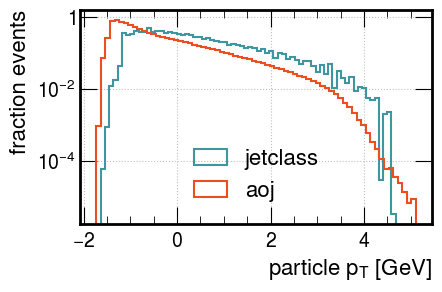

writing figure to analysis/aspen_jets/part_pt__jetclass_vs_aoj.pdf


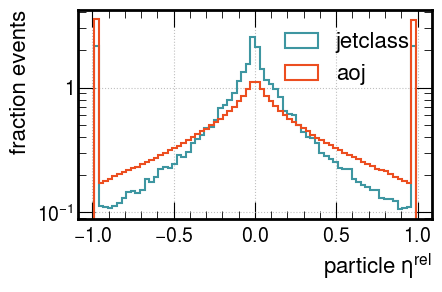

writing figure to analysis/aspen_jets/part_etarel__jetclass_vs_aoj.pdf


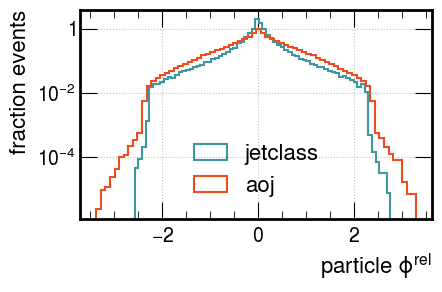

writing figure to analysis/aspen_jets/part_phirel__jetclass_vs_aoj.pdf


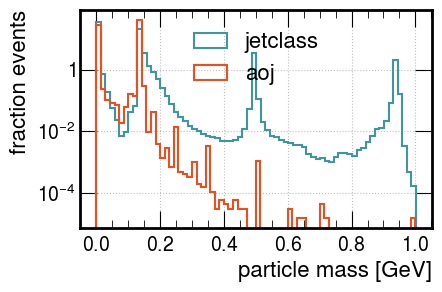

writing figure to analysis/aspen_jets/part_mass__jetclass_vs_aoj.pdf


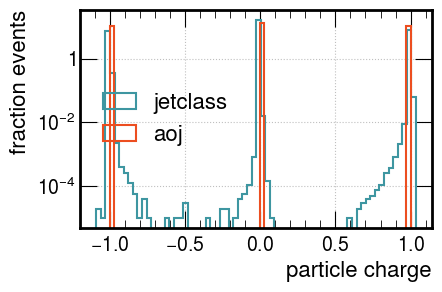

writing figure to analysis/aspen_jets/part_charge__jetclass_vs_aoj.pdf


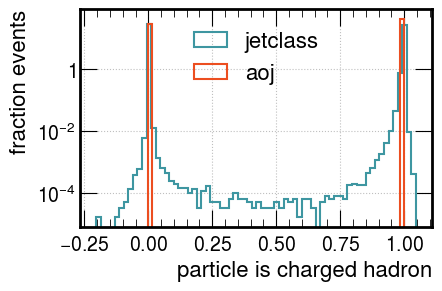

writing figure to analysis/aspen_jets/part_isChargedHadron__jetclass_vs_aoj.pdf


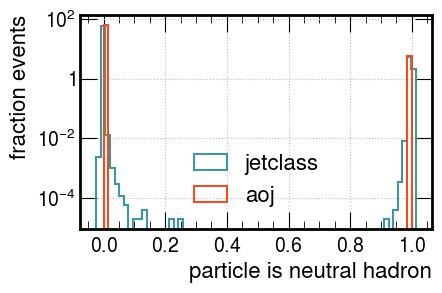

writing figure to analysis/aspen_jets/part_isNeutralHadron__jetclass_vs_aoj.pdf


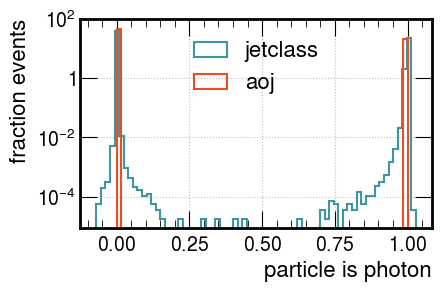

writing figure to analysis/aspen_jets/part_isPhoton__jetclass_vs_aoj.pdf


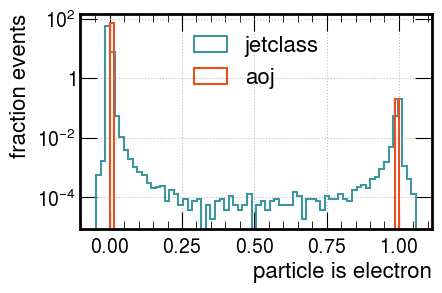

writing figure to analysis/aspen_jets/part_isElectron__jetclass_vs_aoj.pdf


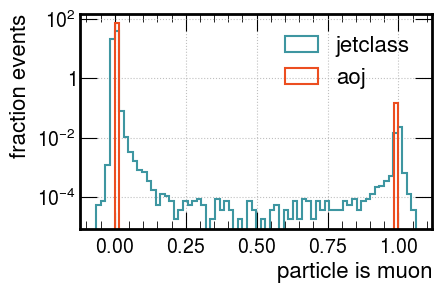

writing figure to analysis/aspen_jets/part_isMuon__jetclass_vs_aoj.pdf


/tmp/ipykernel_1736016/1871177517.py:43: RuntimeWarning: divide by zero encountered in divide
  jetclass_flat = jetclass_d0val / jetclass_d0err


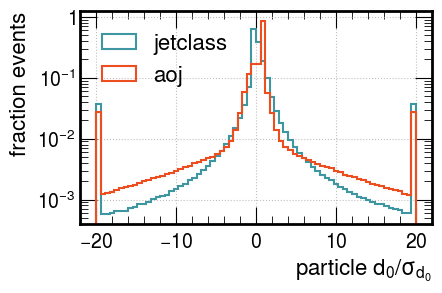

writing figure to analysis/aspen_jets/part_d0sig__jetclass_vs_aoj.pdf


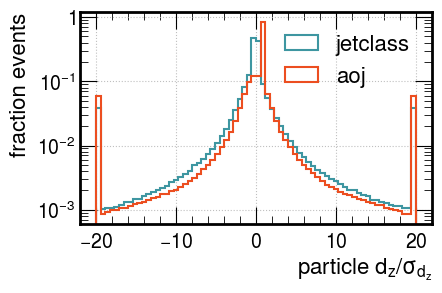

writing figure to analysis/aspen_jets/part_dzsig__jetclass_vs_aoj.pdf


In [9]:
import os
import sys

deps_path = "/home/users/w/wozniak/.local/ntp4jets-deps"
if deps_path not in sys.path:
    sys.path.insert(0, deps_path)

import heputl.plotting.oneD as heplt

output_dir = "analysis/aspen_jets"
os.makedirs(output_dir, exist_ok=True)

jetclass_feature_names = list(cfg.data.dataset_kwargs_common.feature_dict.keys())
aoj_feature_names = list(cfg_aoj.data.dataset_kwargs_common.feature_dict.keys())

FEATURE_LABELS = {
    "part_pt": r"particle $p_\mathrm{T}$ [GeV]",
    "part_etarel": r"particle $\eta^\mathrm{rel}$",
    "part_phirel": r"particle $\phi^\mathrm{rel}$",
    "part_mass": r"particle mass [GeV]",
    "part_charge": r"particle charge",
    "part_isChargedHadron": r"particle is charged hadron",
    "part_isNeutralHadron": r"particle is neutral hadron",
    "part_isPhoton": r"particle is photon",
    "part_isElectron": r"particle is electron",
    "part_isMuon": r"particle is muon",
    "part_d0sig": r"particle $d_0/\sigma_{d_0}$",
    "part_dzsig": r"particle $d_z/\sigma_{d_z}$",
}

ETAREL_CLIP = 0.99
SIG_CLIP = 20

# skip particle index 0 for jetclass: the tokenized-data config prepends an all-zero
# "start token" particle to every jet, which isn't a real constituent
jetclass_mask = jetclass_part_mask[:, 1:]
aoj_mask = aoj_part_mask

for feat, label in FEATURE_LABELS.items():
    if feat == "part_d0sig":
        jetclass_d0val = jetclass_part_features[:, 1:, jetclass_feature_names.index("part_d0val")][jetclass_mask]
        jetclass_d0err = jetclass_part_features[:, 1:, jetclass_feature_names.index("part_d0err")][jetclass_mask]
        jetclass_flat = jetclass_d0val / jetclass_d0err

        # AOJ's -1/-1 placeholder for particles with no valid track fit divides to exactly 1.0,
        # not a real significance value - drop it like the other non-finite placeholders below
        aoj_d0val = aoj_part_features[..., aoj_feature_names.index("part_d0val")][aoj_mask]
        aoj_d0err = aoj_part_features[..., aoj_feature_names.index("part_d0err")][aoj_mask]
        aoj_flat = np.where((aoj_d0val == -1) & (aoj_d0err == -1), np.nan, aoj_d0val / aoj_d0err)
    elif feat == "part_dzsig":
        jetclass_dzval = jetclass_part_features[:, 1:, jetclass_feature_names.index("part_dzval")][jetclass_mask]
        jetclass_dzerr = jetclass_part_features[:, 1:, jetclass_feature_names.index("part_dzerr")][jetclass_mask]
        jetclass_flat = jetclass_dzval / jetclass_dzerr

        aoj_dzval = aoj_part_features[..., aoj_feature_names.index("part_dzval")][aoj_mask]
        aoj_dzerr = aoj_part_features[..., aoj_feature_names.index("part_dzerr")][aoj_mask]
        aoj_flat = np.where((aoj_dzval == -1) & (aoj_dzerr == -1), np.nan, aoj_dzval / aoj_dzerr)
    else:
        jetclass_idx = jetclass_feature_names.index(feat)
        jetclass_flat = jetclass_part_features[:, 1:, jetclass_idx][jetclass_mask]

        aoj_idx = aoj_feature_names.index(feat)
        aoj_flat = aoj_part_features[..., aoj_idx][aoj_mask]

    if feat == "part_etarel":
        # clip values beyond +/-0.99 into overflow bins at the edges
        jetclass_flat = np.clip(jetclass_flat, -ETAREL_CLIP, ETAREL_CLIP)
        aoj_flat = np.clip(aoj_flat, -ETAREL_CLIP, ETAREL_CLIP)
    elif feat in ("part_d0sig", "part_dzsig"):
        # clip the long significance tails into overflow bins at +/-20
        jetclass_flat = np.clip(jetclass_flat, -SIG_CLIP, SIG_CLIP)
        aoj_flat = np.clip(aoj_flat, -SIG_CLIP, SIG_CLIP)

    # d0err/dzerr can contain +inf (e.g. from division-by-zero upstream), which breaks
    # heplt's automatic histogram range computation ("supplied range of [-1.0, inf]") -
    # drop non-finite values before plotting
    if not np.isfinite(jetclass_flat).all():
        n_bad = (~np.isfinite(jetclass_flat)).sum()
        print(f"{feat}: dropping {n_bad} non-finite jetclass values")
        jetclass_flat = jetclass_flat[np.isfinite(jetclass_flat)]
    if not np.isfinite(aoj_flat).all():
        n_bad = (~np.isfinite(aoj_flat)).sum()
        print(f"{feat}: dropping {n_bad} non-finite aoj values")
        aoj_flat = aoj_flat[np.isfinite(aoj_flat)]

    heplt.plot_feature_hist_for_n_samples(
        data=[jetclass_flat, aoj_flat],
        sample_names=["jetclass", "aoj"],
        xlabel=label,
        bins=70,
        plot_name=f"{feat}__jetclass_vs_aoj",
        fig_dir=output_dir,
        show_plt=True,
        legend_outside=False,
        fig_size=(5.0, 3.5),
    )

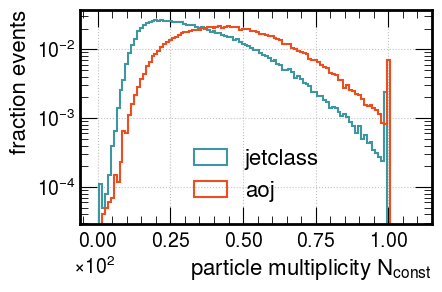

writing figure to analysis/aspen_jets/particle_multiplicity__jetclass_vs_aoj.pdf


In [13]:
jetclass_mult = jetclass_part_mask[:, 1:].sum(axis=1)
aoj_mult = aoj_part_mask.sum(axis=1)

max_mult = max(jetclass_mult.max(), aoj_mult.max())
mult_bins = np.arange(-0.5, max_mult + 10, 1)

heplt.plot_feature_hist_for_n_samples(
    data=[jetclass_mult, aoj_mult],
    sample_names=["jetclass", "aoj"],
    xlabel=r"particle multiplicity $N_\mathrm{const}$",
    bins=mult_bins,
    plot_name="particle_multiplicity__jetclass_vs_aoj",
    fig_dir=output_dir,
    show_plt=True,
    legend_outside=False,
    fig_size=(5.0, 3.5),
)